In [ ]:
import datasets as ds

import cv2
import numpy as np
from PIL import Image

import matplotlib.pyplot as plt
import pandas as pd
import time
import seaborn as sns

In [ ]:
# dataset = ds.load_dataset(
#     "shunk031/MSCOCO",
#     year=2017,
#     coco_task="person_keypoints",
#     decode_rle=True, # True if Run-length Encoding (RLE) is to be decoded and converted to binary mask.
#     trust_remote_code=True
# )

# alternative
dataset = ds.load_dataset('whyen-wang/coco_keypoints')

In [5]:
train = pd.DataFrame(dataset['train'][:5000])

In [ ]:
train.head()

In [42]:
#add feature: visible = keypoints != [0,0,0]
train['visible'] = train['keypoints'].apply(lambda x: [1 if x[i] != 0 else 0 for i in range(0, len(x), 3)])

In [ ]:
from PIL import ImageStat

def analyze_image_properties(image):
    # Convert image to grayscale
    grayscale_image = image.convert("L")
    
    # Calculate image statistics
    stat = ImageStat.Stat(grayscale_image)
    
    # Calculate mean brightness
    mean_brightness = stat.mean[0]
    
    # Calculate image resolution
    resolution = image.size
    width, height = resolution
    
    return mean_brightness, width, height

# Initialize lists to store analysis results
brightness_list = []
width_list = []
height_list = []

# Analyze each image in the dataset
for img in train['image']:
    mean_brightness, width, height = analyze_image_properties(img)
    brightness_list.append(mean_brightness)
    width_list.append(width)
    height_list.append(height)

# Convert lists to DataFrame for better visualization
analysis_df = pd.DataFrame({
    'Brightness': brightness_list,
    'Width': width_list,
    'Height': height_list
})

# Display the analysis results
print(analysis_df.describe())


In [44]:
import numpy as np
from PIL import Image, ImageDraw

def visualize(example):
    image = example['image']
    bboxes = example['bboxes']
    keypoints = example['keypoints']
    
    # Convert PIL image to a format that can be drawn on
    if isinstance(image, Image.Image):
        image = image.copy()
    else:
        image = Image.fromarray(image)
    
    draw = ImageDraw.Draw(image)
    
    # List of labels to cycle through
    labels = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M", "N", "O", "P", "Q"]
    colors = ["red", "yellow", "lime"]
    
    # Define connections between keypoints
    connections = [
        (0, 1), (0, 2), (1, 3), (2, 4), (5,6), (5, 7), (7, 9), (6, 8), (8, 10),
        (5, 11), (6, 12), (11, 13), (13, 15), (12, 14), (14, 16)
    ]
    
      # Draw connections between keypoints
    for ks in keypoints:
        for connection in connections:
            start, end = connection
            if ks[start][2] != 0 and ks[end][2] != 0:  # Only draw connections if both keypoints are visible
                draw.line([ks[start][0], ks[start][1], ks[end][0], ks[end][1]], fill="blue", width=2)

    # Draw keypoints with labels
    label_index = 0
    for ks in keypoints:
        for k in ks:
            x, y, v = k
            if v != 0:  # Only draw keypoints with visibility flag
                label = labels[label_index % len(labels)]
                color = colors[v % len(colors)]
                draw.ellipse([x-1.5, y-1.5, x+1.5, y+1.5], fill=color, outline=color)
                draw.text((x+3, y-3), label + str(v), fill="white", stroke_fill="black", stroke_width=0.5)
            label_index += 1
        label_index = 0
    
  
    
    return image

In [ ]:
range_img = range(2320,2380)

for i in range_img:
    example = train.iloc[i]
    visualized_image = visualize(example)
    visualized_image.show()

# Keypoints Structure
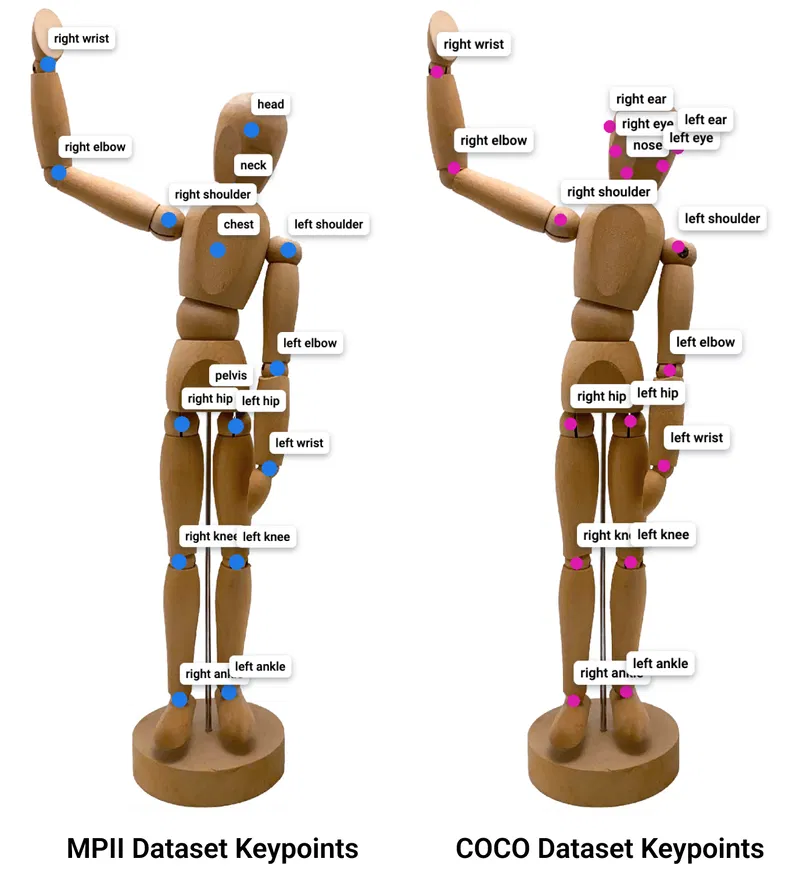 

- A -> Nose
- B -> Left Eye
- C -> Right Eye
- D -> Left Ear
- E -> Right Ear
- F -> Left Shoulder
- G - > Right Shoulder
- H -> Left Elbow
- I -> Right Elbow
- J -> Left Wrist
- K -> Right Wrist
- L -> Left Hip
- M -> Right Hip
- N -> Left Knee
- O -> Right Knee
- P -> Left Foot
- Q -> Right Foot

(17 keypoints)

- Uses sames images but zoomed in
- Uses images with no humans on it
- Cut Images
- Low light Images
- Blurred in Background (3999)
- Motion Blur Images
- Missing keypoints have [0,0,0] coordinates (x,y,v)
    - (x,y) coordinates
    - v == 0 > not visible, v == 1 > labeled but not visible, v == 2 > labeled and visible
- Points do not have a label (same order can have different points)

In [ ]:
import torch
if torch.backends.mps.is_available():
    mps_device = torch.device("mps")
    x = torch.ones(1, device=mps_device)
    print (x)
else:
    print ("MPS device not found.")

In [ ]:
# Train simple CNN model
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
from torch.utils.data import DataLoader, random_split
from torchvision.models import resnet18

class KeypointDataset(torch.utils.data.Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        example = self.dataframe.iloc[idx]
        image = example['image']
        keypoints = example['keypoints']
        
        if self.transform:
            image = self.transform(image)
        
        return image, keypoints
    
# Define transformations to be applied to the images
transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor()
])

# Create dataset and dataloader
dataset = KeypointDataset(train, transform=transform)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)

# Define the model
class KeypointModel(nn.Module):
    def __init__(self):
        super(KeypointModel, self).__init__()
        self.resnet = resnet18(pretrained=True)
        self.fc = nn.Linear(1000, 51)x
    
    def forward(self, x):
        x = self.resnet(x)
        x = self.fc(x)
        return x
    
model = KeypointModel()

# Define loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train the model
num_epochs = 5
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model.to(device)

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    for images, keypoints in train_loader:
        images, keypoints = images.to(device), keypoints.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        
        loss = criterion(outputs, keypoints)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
    
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, keypoints in val_loader:
            images, keypoints = images.to(device), keypoints.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, keypoints)
            
            val_loss += loss.item()
    
    print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

